# Model 2: LightGBM Classifier for Low-TF Multi-Cancer Detection
### Step-by-Step Model Building & Validation

**What is LightGBM in simple words?**  
LightGBM stands for *Light Gradient Boosting Machine*. Like XGBoost, it builds a forest of decision trees.  
However, while XGBoost grows trees row-by-row (level-wise), LightGBM grows trees by picking the single leaf with the largest loss reduction (leaf-wise).  

**Why use LightGBM alongside XGBoost?**  
Because LightGBM explores different tree splits than XGBoost, it often discovers alternative feature combinations in the 256 motif dimensions, making it a great complementary partner!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve
import lightgbm as lgb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print("LightGBM loaded successfully!")

LightGBM loaded successfully!


## Step 1: Load Data & Configure Zero-Leakage GroupKFold

In [2]:
data_path = Path("../../data/processed/merged_features.parquet")
df = pd.read_parquet(data_path)

meta_cols = {"sample_id", "patient_id", "condition", "cancer_type", "stage", "measured_tf", "is_cancer"}
feature_cols = [c for c in df.columns if c not in meta_cols and np.issubdtype(df[c].dtype, np.number)]

X = df[feature_cols].values
y = df["is_cancer"].values
groups = df["patient_id"].values

gkf = GroupKFold(n_splits=5)
oof_preds = np.zeros(len(df))
feature_importances = np.zeros(len(feature_cols))

print(f"Training LightGBM on {len(feature_cols)} features with patient grouping...")
for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups), 1):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X[train_idx])
    X_val = scaler.transform(X[val_idx])
    
    clf = lgb.LGBMClassifier(
        n_estimators=120, max_depth=3, num_leaves=8, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
        min_child_samples=2, random_state=42, verbose=-1
    )
    clf.fit(X_train, y[train_idx])
    
    oof_preds[val_idx] = clf.predict_proba(X_val)[:, 1]
    feature_importances += clf.feature_importances_ / 5.0

overall_auc = roc_auc_score(y, oof_preds)
print(f"LightGBM Overall Out-of-Fold ROC-AUC: {overall_auc:.4f}")

Training LightGBM on 265 features with patient grouping...
LightGBM Overall Out-of-Fold ROC-AUC: 0.9930


c:\Users\angel\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\angel\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\angel\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\angel\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\angel\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: U

## Step 2: LightGBM Feature Importance

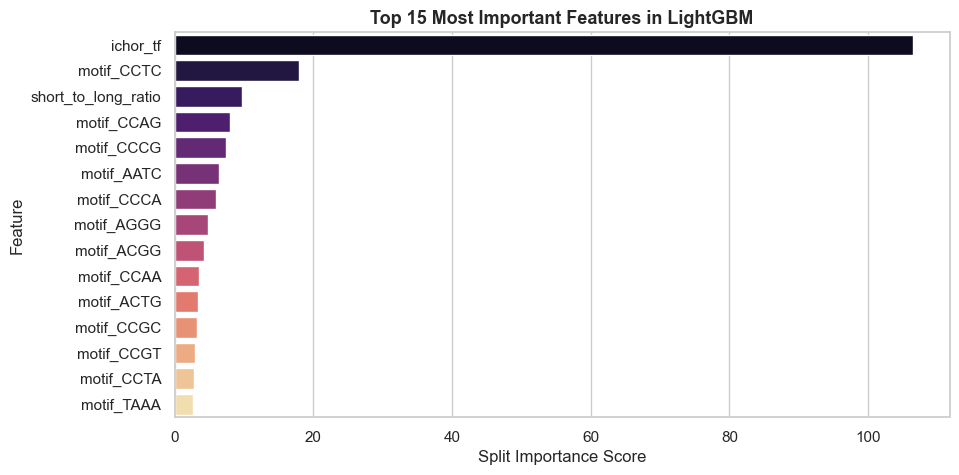

In [3]:
imp_df = pd.DataFrame({"Feature": feature_cols, "Importance": feature_importances})
top15 = imp_df.sort_values(by="Importance", ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(data=top15, x="Importance", y="Feature", palette="magma", hue="Feature", legend=False)
plt.title("Top 15 Most Important Features in LightGBM", fontsize=13, fontweight="bold")
plt.xlabel("Split Importance Score")
plt.show()

## Step 3: Sensitivity at 95% Specificity & Save Predictions

In [4]:
healthy_scores = oof_preds[y == 0]
thresh_95 = float(np.percentile(healthy_scores, 95))
print(f"LightGBM 95% Specificity Threshold: {thresh_95:.4f}")

df["pred_lightgbm"] = oof_preds
df["tf_tier"] = df["measured_tf"].apply(lambda tf: "TF >= 10%" if tf >= 0.10 else "5% <= TF < 10%" if tf >= 0.05 else "1% <= TF < 5%" if tf >= 0.01 else "0.1% <= TF < 1%")

print("\n=== LightGBM Sensitivity across Tumor Fraction Tiers ===")
for tier in ["TF >= 10%", "5% <= TF < 10%", "1% <= TF < 5%", "0.1% <= TF < 1%"]:
    sub = df[(df["tf_tier"] == tier) & (df["is_cancer"] == 1)]
    if len(sub) > 0:
        sens = np.mean(sub["pred_lightgbm"] >= thresh_95)
        print(f"  Tier {tier:20s}: Sensitivity = {sens * 100:.1f}% (N={len(sub)} samples)")

out_pred = Path("../../results/oof_lightgbm.csv")
df[["sample_id", "patient_id", "condition", "measured_tf", "is_cancer", "pred_lightgbm"]].to_csv(out_pred, index=False)
print(f"\nSaved out-of-fold predictions to: {out_pred}")

LightGBM 95% Specificity Threshold: 0.1297

=== LightGBM Sensitivity across Tumor Fraction Tiers ===
  Tier 5% <= TF < 10%      : Sensitivity = 97.6% (N=41 samples)

Saved out-of-fold predictions to: ..\..\results\oof_lightgbm.csv
